# Các Lịch giảm nhiệt độ trong Simulated Annealing (Cooling Schedules)

*Tác giả gốc: Michael Hahsler - Dịch & Bổ sung thực nghiệm: Nhóm sinh viên Lab 03*

Notebook này trình bày và so sánh các chiến lược hạ nhiệt độ (Cooling Schedules) phổ biến trong giải thuật Simulated Annealing:
1. **Lịch Hàm mũ (Exponential Schedule)**: $T(t) = T_0 \cdot lpha^t$ với $lpha \in (0, 1)$
2. **Lịch Tuyến tính (Linear Schedule)**: $T(t) = T_0 - \eta \cdot t$
3. **Lịch Tôi nhanh (Fast Simulated Annealing)**: $T(t) = rac{T_0}{1 + t}$
4. **Lịch Logarithmic (Cổ điển)**: $T(t) = rac{T_0}{\ln(1 + t)}, t > 0$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Định nghĩa các Lịch giảm nhiệt độ

### 1.1 Lịch Hàm mũ (Exponential Schedule)
Hạ nhiệt độ theo cấp số nhân. Với $lpha$ thường chọn từ 0.8 đến 0.99, đây là lịch nhiệt phổ biến nhất trong thực tế.

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### 1.2 Lịch Tuyến tính (Linear Schedule)
Hạ nhiệt độ đều đặn một lượng cố định $\eta$ sau mỗi bước lặp.

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### 1.3 Lịch Tôi nhanh (Fast Simulated Annealing)
Nhiệt độ giảm tỉ lệ nghịch với thời gian: $T(t) = T_0 / (1 + t)$.

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### 1.4 Lịch Logarithmic (Cổ điển - Hajek 1988)
Nếu $T_0$ đủ lớn, lịch này đảm bảo về mặt lý thuyết sẽ hội tụ về nghiệm tối ưu toàn cục khi thời gian tiến tới vô cùng. Tuy nhiên tốc độ làm nguội cực kỳ chậm.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## 2. So sánh Trực quan giữa các Lịch giảm nhiệt độ

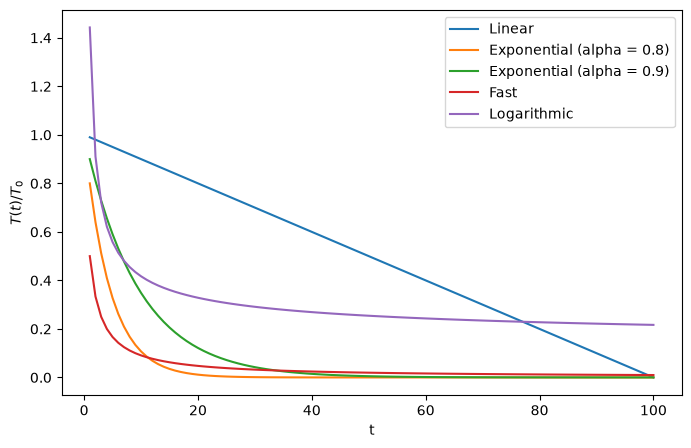

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## 3. Khảo sát Xác suất chấp nhận bước xấu $P(\Delta, T)$ theo thời gian
Theo lý thuyết Metropolis, khi gặp bước xấu làm tăng hàm chi phí $\Delta > 0$, xác suất chấp nhận là:
$$P(	ext{accept}) = \exp\left(-rac{\Delta}{T(t)}ight)$$
Dưới đây là đồ thị xác suất chấp nhận bước xấu $\Delta = 2$ theo các lịch nhiệt độ.

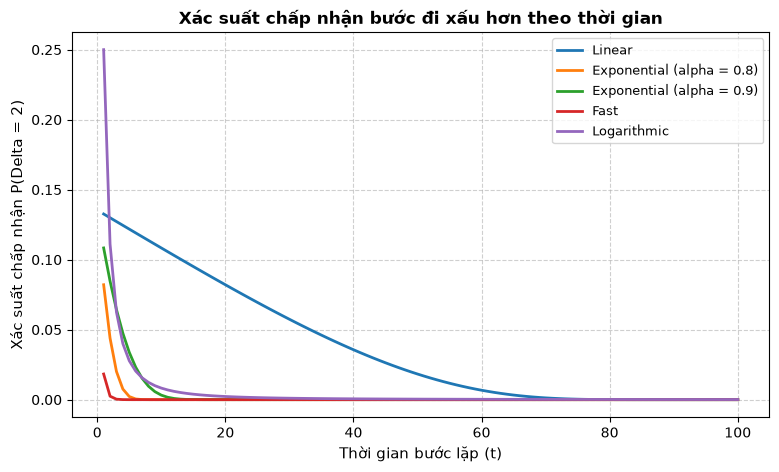

In [7]:
# Khảo sát xác suất chấp nhận bước xấu Delta = 2
delta = 2.0
plt.figure(figsize=(9, 5))
for name, temperature in schedules.items():
    safe_T = np.maximum(temperature, 1e-6)
    p = np.exp(-delta / safe_T)
    p[temperature <= 0] = 0
    plt.plot(time, p, label=name, linewidth=2)

plt.xlabel("Thời gian bước lặp (t)", fontsize=11)
plt.ylabel(f"Xác suất chấp nhận P(Delta = {int(delta)})", fontsize=11)
plt.title("Xác suất chấp nhận bước đi xấu hơn theo thời gian", fontsize=12, weight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9)
plt.show()


### Nhận xét & Đánh giá (Bài 5):
1. **Lịch Logarithmic:** Giảm nhiệt độ chậm nhất. Xác suất chấp nhận bước xấu được duy trì ở mức cao trong thời gian rất dài, giúp thuật toán khám phá sâu nhưng mất rất nhiều thời gian để hội tụ.
2. **Lịch Fast Annealing:** Giảm nhanh ở giai đoạn đầu nhưng có đuôi dài (heavy tail), cho phép vừa khám phá ban đầu vừa duy trì khả năng thoát bẫy cục bộ ở các bước sau.
3. **Lịch Tuyến tính (Linear):** Giảm cứng nhắc về 0, dễ bị đông cứng sớm nếu bước giảm $\eta$ quá lớn.
4. **Lịch Hàm mũ (Exponential):** Tùy chỉnh linh hoạt bằng tham số $lpha$. Với $lpha \in [0.90, 0.98]$, thuật toán chuyển đổi mượt mà từ giai đoạn *khám phá (exploration)* sang giai đoạn *khai thác (exploitation)*, mang lại hiệu quả thực nghiệm cao nhất.

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)